# Une surcouche de règles écrites par LLM améliore-t-elle un détecteur de fraude gelé mieux qu'une extraction de règles classique ou un réentraînement pondéré ?

> **En bref.** Aucune conclusion possible : la surcouche n'a quasiment pas agi avec un petit LLM, et tous les écarts sont dans le bruit. Le dispositif de comparaison est correct, mais seul le passage à l'échelle complète pourrait trancher. ΔR@P (points, vs cibles de production) : 0,224 [-1,49 ; 4,98] pour Surcouche LLM (Qwen/Qwen3-0.6B), contre -0,673 [-4,52 ; 2,93] pour Réentraînement pondéré (36037 exemples de test, échelle réduite, chiffres indicatifs).

| | |
|---|---|
| **Question** | Sur les mois ultérieurs à l'entraînement d'un XGBoost gelé, la surcouche de règles LLM filtrées par lift ne dégrade pas le rappel à précision égale (ΔR@P ≥ 0, IC95 % excluant −0,5 point) et ne bat pas de plus de 0,3 point une extraction de règles par arbre de décision sur la même fenêtre d'adaptation. |
| **Référence** | XGBoost gelé, règles par arbre et réentraînement pondéré — Détecteur XGBoost entraîné sur les premiers mois puis gelé ; correctifs de référence : règles extraites par arbre peu profond sur la fenêtre d'adaptation, et poursuite d'entraînement pondérée. |
| **Nouvelle approche** | Surcouche de règles écrites par LLM ouverts — Les valeurs SHAP du modèle gelé repèrent les variables sous-pondérées ; plusieurs LLM proposent chacun 10 jeux de règles (conjonctions de seuils) ; un filtre par lift garde les règles utiles ; chaque règle ajoute log(lift) au logit ; le score est remappé sur l'échelle d'origine. |
| **Données publiques** | [`jAEhEEkIM/operationbench-baf-raw`](https://huggingface.co/datasets/jAEhEEkIM/operationbench-baf-raw) (default) |
| **Métrique principale** | ΔR@P (points, vs cibles de production) (à maximiser) |

**Sommaire** — 0. Mise en route · 1. La question · 2. Les données · 3. L'approche de référence · 4. La nouvelle approche · 5. Évaluation · 6. Analyse des résultats · 7. Bilan

**Trois façons d'exécuter ce notebook** (cellule de paramètres, section 0) :

| Réglage | À quoi ça sert |
|---|---|
| `PHASE = "public"`, `SCALE = "reduced"` | vérifier que tout fonctionne : quelques minutes sur CPU, sur un échantillon |
| `PHASE = "public"`, `SCALE = "full"` | reproduire les résultats publiés, sur tout le jeu public |
| `PHASE = "private"` | rejouer le même protocole sur vos données, dans votre environnement (voir le README) |

Les sorties affichées sont celles de l'échelle réduite (`SCALE = "reduced"`).

## 0. Mise en route

Trois réglages suffisent : la **phase** (quelles données), l'**échelle** (combien de données et quels modèles) et la **graine** (mêmes tirages, mêmes résultats). Le même code sert aux deux phases : seule la source des données change.

- `PHASE = "public"` charge le jeu public ; `PHASE = "private"` lit vos données d'après `PRIVATE_CONFIG` (cellule suivante) et appelle vos services internes. En phase `private`, aucune donnée brute n'est affichée.
- `SCALE = "reduced"` prend un petit échantillon et, si besoin, des modèles plus petits de la même famille : c'est un test de la mécanique, ses chiffres ne valent pas résultat. `SCALE = "full"` utilise tout le jeu.
- Les fonctions communes (chargement des données internes, appels de services, intervalles de confiance, figures, enregistrement des résultats) sont dans `helpers.py`, à côté du notebook.

Fonctions de `helpers.py` utilisées ici :

| Fonction | Rôle |
|---|---|
| `set_seed` | Graine unique pour random, numpy et torch (s'ils sont présents) : résultats reproductibles. |
| `device` | Matériel de calcul disponible : « cuda » (GPU NVIDIA), « mps » (GPU Apple) ou « cpu ». |
| `sample_size` | Nombre d'exemples à utiliser : `reduced` à l'échelle réduite, `full` (None = tout le jeu) à l'échelle complète. |
| `by_scale` | Valeur qui dépend de l'échelle : modèle substitut, nombre d'époques, de pas ou d'exemples. |
| `model_path` | Chemin à passer à `from_pretrained`, dans les deux phases : l'identifiant Hugging Face, ou son dossier local sous LOCAL_MODELS_DIR (org--nom ou org/nom), seul accessible dans un environnement sans Internet. |
| `llm_chat` | Appel chat/completions. Avec `schema` (JSON Schema), rend l'objet décodé (None si la sortie est illisible) : sortie structurée si le service la prend en charge (mode strict si le schéma s'y prête), sinon consigne dans le prompt et décodage tolérant. |
| `load_private_data` | Jeu de la phase « private » : DataFrame aux colonnes attendues, lu dans PRIVATE_CONFIG['data'] (ou PRIVATE_DATA), fichier ou dossier (csv, tsv, parquet, jsonl, json, xlsx). |
| `preview` | Premières lignes en phase « public » ; en phase « private », seulement la structure (sauf SHOW_EXAMPLES=1). |
| `timer` | Mesure une durée en millisecondes : `with timer(liste): ...` ajoute la durée à `liste`. |
| `latency_stats` | Médiane (p50) et 95e centile (p95) d'une liste de durées en millisecondes. |
| `bootstrap_ci` | Valeur de `metric(y_true, y_pred)` et son intervalle de confiance à 95 % par bootstrap : (valeur, bas, haut). |
| `save_results` | Valide puis écrit results_<phase>.json dans le dossier des résultats. Structure attendue : |
| `results_table` | Tableau comparatif : une ligne par approche, chaque métrique avec son intervalle de confiance. |
| `save_figure` | Enregistre la figure (figures/<name>.png), l'affiche avec sa légende et la ferme ; ne renvoie rien. |
| `plot_comparison` | Figure de synthèse : une barre par approche et par métrique, avec l'intervalle de confiance à 95 % quand il existe. Par défaut, la métrique principale puis jusqu'à trois autres métriques. Une métrique sans objet pour une approche (None) n'a pas de barre pour elle. |

In [1]:
PHASE = "public"        # "public" : jeu public ; "private" : vos données, dans votre environnement
SCALE = "reduced"       # "reduced" : échantillon, quelques minutes sur CPU ; "full" : tout le jeu
SEED = 42               # graine : mêmes tirages, mêmes résultats
OUTPUT_DIR = "outputs"  # résultats (results_<phase>.json) et figures

### Configuration pour vos données

À modifier seulement pour `PHASE = "private"`. Chaque entrée est expliquée en commentaire ; les valeurs par défaut viennent des variables d'environnement décrites dans `private.env.example`. Au lancement, une liste de contrôle vérifie le jeu, les colonnes, les modèles et les services, et s'arrête sur ce qui manque avant tout calcul.

In [3]:
# Configuration pour vos données (PHASE = "private") : seule cellule à adapter.
# Les valeurs par défaut viennent de l'environnement (modèle : private.env.example).
# Aucune clé ici : elle vient de <SERVICE>_API_KEY, d'un fichier de secret monté (<SERVICE>_API_KEY_FILE) ou d'une saisie masquée.
import os

PRIVATE_CONFIG = {
    # Jeu de données : un fichier (csv, tsv, parquet, jsonl, json, xlsx) ou un dossier de fichiers de même structure.
    "data": os.environ.get("PRIVATE_DATA", ""),
    # Colonne attendue par le notebook -> nom de la colonne dans votre jeu (ne modifier que la partie droite).
    "columns": {'is_fraud': 'is_fraud', 'event_time': 'event_time', 'features': 'features', 'frozen_score': 'frozen_score', 'was_filtered_upstream': 'was_filtered_upstream'},
    # Colonnes qui contiennent des chemins de fichiers (relatifs au fichier de données qui les cite, ou absolus).
    "path_columns": [],
    "max_rows": None,                         # plafond facultatif (échantillon aléatoire reproductible)
    "csv": {"sep": None, "encoding": None},   # None : séparateur et encodage devinés (« ; », Windows-1252…)
    # Poids des modèles copiés localement (dossiers org--nom/, script download_models.py), pour travailler sans Internet.
    "models_dir": os.environ.get("LOCAL_MODELS_DIR", ""),
    "models": {'reduced': ['Qwen/Qwen3-0.6B'], 'full': ['HuggingFaceTB/SmolLM3-3B', 'Qwen/Qwen2.5-3B-Instruct', 'Qwen/Qwen3-1.7B']},
    # Autorité de certification d'entreprise (fichier PEM) pour les appels HTTPS internes ; vide sinon.
    "ca_bundle": os.environ.get("SSL_CERT_FILE", ""),
    "llmaas": {"base_url": os.environ.get("LLMAAS_BASE_URL", ""), "model": os.environ.get("LLMAAS_MODEL", ""),
               "api_key_file": os.environ.get("LLMAAS_API_KEY_FILE", ""),
               "headers": {}},  # en-têtes exigés par votre passerelle, s'il y en a
}

### Dépendances et initialisation

Les versions exactes utilisées pour les résultats publiés sont dans `requirements.txt`. Les paquets propres à cette expérience s'installent depuis le notebook avec `INSTALL_DEPENDENCIES=1`.

In [4]:
# Paquets propres à cette expérience (en plus de requirements.txt).
EXTRA_PACKAGES = []
import os, subprocess, sys
if EXTRA_PACKAGES and os.environ.get("INSTALL_DEPENDENCIES") == "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *EXTRA_PACKAGES])

In [5]:
from helpers import *  # fonctions communes (voir le tableau ci-dessus)

configure(phase=PHASE, scale=SCALE, seed=SEED, output_dir=OUTPUT_DIR)
apply_private_config(PRIVATE_CONFIG)  # phase private : liste de contrôle, arrêt si quelque chose manque
prepare_environment()                 # télémétrie coupée ; hors ligne si les modèles sont locaux
use_plot_style()
show_configuration()

PHASE=public  SCALE=reduced  SEED=42  device=cpu  python=3.12.16
service LLM (convention OpenAI)               LLMAAS_BASE_URL=—  LLMAAS_MODEL=—  clé absente
service de transcription (convention OpenAI)  STTAAS_BASE_URL=—  STTAAS_MODEL=—  clé absente
données internes : —  modèles locaux : —


## 1. La question

Un détecteur de fraude à **arbres boostés** est souvent **gelé** une fois déployé. Le réentraîner oblige à le redéployer, et ses données d'entraînement ne contiennent que le trafic déjà approuvé par des filtres en amont. C'est un **biais de sélection**. Il garde donc des **angles morts** : des fraudes qu'il note trop bas.

Une publication récente (*Patching the Blind Spots*, arXiv 2611.08714, novembre 2026) propose de les corriger **sans toucher au modèle**. Des LLM à poids ouverts écrivent des règles simples, et ces règles s'ajoutent au score. Les auteurs annoncent **+2,26 points de rappel** à précision égale sur un jeu industriel non public. Sur le jeu public BAF, ils ne revendiquent qu'une **absence de dégradation**. Ils ne comparent pas la méthode à une extraction de règles classique.

### L'idée, par une analogie

Le modèle gelé ressemble à un analyste expérimenté qu'on ne peut plus former. On lui colle des **post-it** : « si cet indicateur dépasse tel seuil, méfie-toi davantage ». Chaque post-it pèse selon ce qu'il a prouvé sur un mois récent. Si on retire les post-it, l'analyste juge comme avant.

1. Les **valeurs SHAP** du modèle gelé montrent quelles variables il **sous-pondère** par rapport à leur signal réel.
2. Un LLM reçoit un résumé du modèle et de ces écarts, puis propose des règles : des conjonctions de seuils, centrées de préférence sur les variables sous-pondérées.
3. On ne garde une règle que si son **lift** dépasse 1 et qu'elle se déclenche au moins 3 fois sur la fenêtre d'adaptation.
4. Chaque règle ajoute $\log(\text{lift})$ au score en **logit**, par tranche de seuil d'alerte.
5. On moyenne les tirages, puis on **remappe** le score sur l'échelle d'origine pour que les seuils d'alerte restent valables.

### Ce que la comparaison permet de décider

- **Hypothèse** : la surcouche LLM ne dégrade pas le rappel à précision égale (IC 95 % de l'écart apparié au gelé au-dessus de −0,5 point). Elle ne bat pas de plus de 0,3 point une extraction de règles par **arbre de décision** soumise aux mêmes filtres.
- **Références** : le modèle gelé seul, les règles extraites par un arbre de profondeur 3, et un **réentraînement pondéré** (des arbres ajoutés qui insistent sur les fraudes manquées).
- **Décision** : si la surcouche LLM ne fait pas mieux que l'arbre, son coût (génération, revue des règles) n'est pas justifié.

## 2. Les données

### Bibliothèques et réglages des données

On regroupe ici les imports et les constantes de chargement. Le jeu public est une copie du jeu **BAF** (demandes d'ouverture de comptes, services financiers) : environ 1 % de fraudes, 30 variables nommées et une colonne `month` (mois 0 à 7) qui sert d'axe temporel.

- Le split est lu **en flux** (streaming) : seules les premières lignes sont téléchargées.
- À l'échelle réduite, on tire 80 000 lignes au hasard parmi le premier million.
- À l'échelle complète, on garde le premier million entier.

In [6]:
import gc
import json
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import xgboost as xgb
from datasets import load_dataset
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer

DATASET_ID = "jAEhEEkIM/operationbench-baf-raw"  # copie publique du jeu BAF (ouverture de comptes)
DATASET_CONFIG = "default"  # configuration unique du jeu
DATASET_SPLIT = "train"  # split unique, découpé ensuite par mois
MAX_ROWS = 1_000_000  # premier million de lignes : le jeu « Base » si des variantes suivent
STREAM_BATCH = 50_000  # lignes lues par lot pendant la lecture en flux
N_EVENTS = sample_size(reduced=80_000, full=None)  # lignes tirées (None = toutes)
LABEL_COLUMN = "fraud_bool"  # étiquette de fraude (0/1)
PERIOD_COLUMN = "month"  # mois 0 à 7 : axe du découpage chronologique
CATEGORICAL_COLUMNS = ["payment_type", "employment_status", "housing_status", "source", "device_os"]
MAX_CATEGORIES = 10  # modalités les plus fréquentes gardées par variable catégorielle

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Encodage des variables et fenêtres temporelles

Deux fonctions servent aux deux phases :

- `encode_features` produit une matrice numérique. Les variables catégorielles deviennent des **indicatrices** 0/1 (par exemple `housing_status_BA`), et leurs noms restent lisibles par XGBoost comme par un LLM.
- `assign_windows` découpe les périodes dans l'ordre chronologique : 3/8 pour le modèle gelé, 1/8 pour l'**adaptation** (choix des règles), le reste pour l'**évaluation**. Sur BAF, cela donne les mois 0-2, 3 et 4-7.

In [7]:
def safe_name(name: str) -> str:
    """Nom de variable sûr pour XGBoost et un LLM : lettres, chiffres et « _ » seulement."""
    return re.sub(r"[^0-9A-Za-z_]", "_", str(name))


def encode_features(frame: pd.DataFrame, categorical: list[str]) -> pd.DataFrame:
    """Matrice numérique : numériques telles quelles (manquant = -1), catégorielles en indicatrices 0/1."""
    numeric = frame.drop(columns=categorical).apply(pd.to_numeric, errors="coerce").fillna(-1.0)
    parts = [numeric.astype("float32")]
    for column in categorical:
        values = frame[column].astype(str)
        # seule la liste des modalités est lue ici, jamais les étiquettes
        for category in values.value_counts().index[:MAX_CATEGORIES]:
            parts.append((values == category).astype("float32").rename(f"{column}_{category}"))
    encoded = pd.concat(parts, axis=1)
    encoded.columns = [safe_name(c) for c in encoded.columns]
    assert encoded.columns.is_unique, "noms de variables en double après nettoyage"
    return encoded


def assign_windows(period: pd.Series) -> np.ndarray:
    """Fenêtres chronologiques : 3/8 des périodes pour le modèle gelé, 1/8 pour l'adaptation, le reste pour l'évaluation."""
    periods = np.sort(period.unique())
    n_train = max(1, round(3 * len(periods) / 8))
    n_adapt = max(1, round(len(periods) / 8))
    assert len(periods) >= n_train + n_adapt + 1, "il faut au moins trois périodes distinctes"
    return np.where(period.isin(periods[:n_train]), "train",
                    np.where(period.isin(periods[n_train:n_train + n_adapt]), "adapt", "eval"))

### Chargement et contrôles

On lit le split **en flux**, par lots, jusqu'au premier million de lignes, puis on tire l'échantillon avec la graine. On vérifie ensuite :

- que les colonnes attendues sont présentes ;
- que le taux de fraude est proche de 1 % : un taux très différent signalerait des variantes du jeu concaténées ;
- que les mois 0 à 7 sont tous présents.

Les lignes sont triées par mois en gardant leur ordre d'origine (tri stable). Le bootstrap pourra ainsi rééchantillonner des **blocs contigus dans le temps**.

In [8]:
if PHASE == "public":
    # lecture en flux : seules les premières lignes du split sont téléchargées
    stream = load_dataset(DATASET_ID, DATASET_CONFIG, split=DATASET_SPLIT, streaming=True)
    chunks, n_read = [], 0
    for batch in stream.iter(batch_size=STREAM_BATCH):
        chunks.append(pd.DataFrame(batch).iloc[: MAX_ROWS - n_read])
        n_read += len(chunks[-1])
        if n_read >= MAX_ROWS:
            break
    raw_public = pd.concat(chunks, ignore_index=True)
    del stream, chunks
    missing = {LABEL_COLUMN, PERIOD_COLUMN, *CATEGORICAL_COLUMNS} - set(raw_public.columns)
    assert not missing, f"colonnes absentes : {missing}"
    if N_EVENTS is not None and N_EVENTS < len(raw_public):
        raw_public = raw_public.sample(n=N_EVENTS, random_state=SEED).sort_index()
    # ordre chronologique stable : blocs du bootstrap contigus dans le temps
    raw_public = raw_public.sort_values(PERIOD_COLUMN, kind="stable").reset_index(drop=True)
    labels = pd.to_numeric(raw_public[LABEL_COLUMN], errors="raise").astype(int)
    fraud_rate = labels.mean()
    print(f"{n_read:,} lignes lues en flux, {len(raw_public):,} retenues ; taux de fraude {fraud_rate:.2%}")
    assert 0.002 < fraud_rate < 0.05, "taux de fraude inattendu : vérifier le contenu du split"
    assert sorted(int(m) for m in raw_public[PERIOD_COLUMN].unique()) == list(range(8)), "mois 0 à 7 attendus"
    features = encode_features(raw_public.drop(columns=[LABEL_COLUMN, PERIOD_COLUMN]), CATEGORICAL_COLUMNS)
    meta = pd.DataFrame({"label": labels.values,
                         "period": raw_public[PERIOD_COLUMN].astype(int).values,
                         "filtered": False,  # aucun filtre amont connu dans ce jeu
                         "production_score": np.nan})
    print(f"{features.shape[1]} variables après encodage")

1,000,000 lignes lues en flux, 80,000 retenues ; taux de fraude 1.02%
51 variables après encodage


### Figure : volume et taux de fraude par mois

Les barres donnent le nombre d'événements par mois, la courbe le taux de fraude. Les pointillés séparent les trois fenêtres. Si le taux de fraude change d'un mois à l'autre, c'est un **décalage temporel** : le modèle gelé ne l'a pas vu, et la surcouche est censée le rattraper.

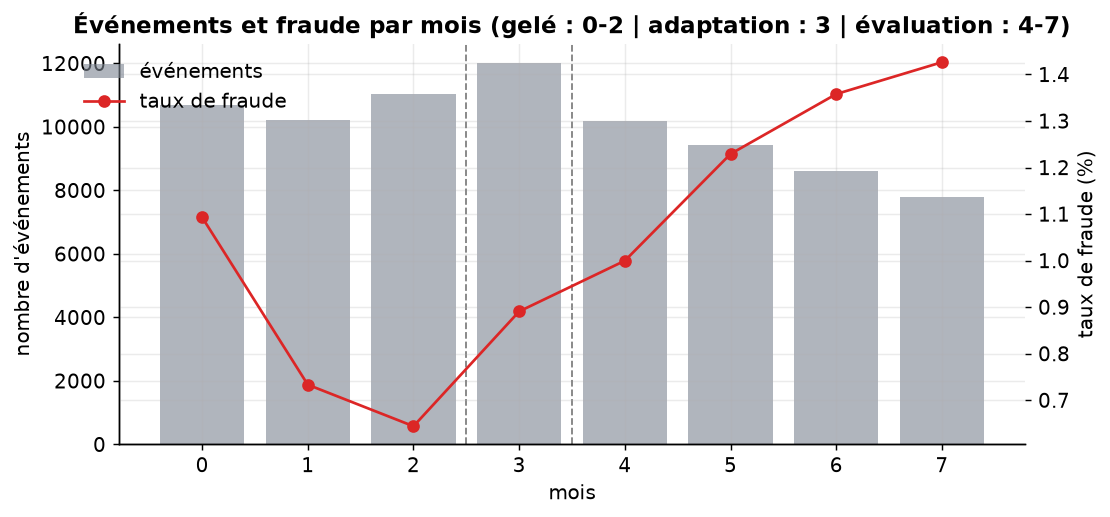

*Figure — Nombre d'événements (barres) et taux de fraude en % (courbe) par mois ; les pointillés séparent la fenêtre du modèle gelé, l'adaptation et l'évaluation.*

In [9]:
if PHASE == "public":
    by_month = meta.groupby("period")["label"].agg(events="size", fraud_rate="mean")
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(by_month.index, by_month["events"], color=COLORS["reference"], alpha=0.6, label="événements")
    ax.set_xlabel("mois")
    ax.set_ylabel("nombre d'événements")
    rate_axis = ax.twinx()
    rate_axis.plot(by_month.index, 100 * by_month["fraud_rate"], color=COLORS["bad"], marker="o", label="taux de fraude")
    rate_axis.set_ylabel("taux de fraude (%)")
    for boundary in (2.5, 3.5):
        ax.axvline(boundary, color="grey", linestyle="--", linewidth=1)
    ax.set_title("Événements et fraude par mois (gelé : 0-2 | adaptation : 3 | évaluation : 4-7)")
    fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88))
    save_figure(fig, "fraud_by_month",
                "Nombre d'événements (barres) et taux de fraude en % (courbe) par mois ; "
                "les pointillés séparent la fenêtre du modèle gelé, l'adaptation et l'évaluation.")

### Aperçu des données

Quelques lignes brutes, pour voir les variables que le LLM devra citer dans ses règles. La valeur −1 code souvent une donnée **manquante** dans BAF.

In [10]:
if PHASE == "public":
    preview(raw_public, n=3)

### Colonnes attendues et jeu factice

Les données internes doivent fournir les colonnes ci-dessous. La colonne `features` contient les variables du détecteur, sous forme d'objet JSON par ligne ou de colonnes supplémentaires : les deux formes sont acceptées.

`make_fake_data` fabrique un jeu **entièrement artificiel** : des opérations de carte de paiement réparties sur huit mois. Il contient un signal volontairement ignoré par le score de production (appareil utilisé avec plusieurs cartes sur le web), pour que la surcouche ait quelque chose à trouver.

In [11]:
PRIVATE_COLUMNS = {
    "is_fraud": "Étiquette de fraude confirmée (0/1)",
    "event_time": "Date de l'événement pour le découpage temporel",
    "features": "Variables du détecteur en production, avec noms explicites",
    "frozen_score": "Score du détecteur en production au moment de la décision",
    "was_filtered_upstream": "Événement bloqué par un filtre amont (mesure du biais de sélection)",
}
N_FAKE = 8000  # assez d'événements pour avoir des fraudes dans chaque fenêtre


def make_fake_data(n: int) -> pd.DataFrame:
    """Jeu factice plausible (opérations de carte de paiement sur huit mois), sans aucune donnée réelle."""
    rng = np.random.default_rng(SEED)
    amount = rng.lognormal(3.5, 1.1, n)
    velocity_1h = rng.poisson(1.5, n)
    account_age_days = rng.integers(1, 3650, n)
    risk_score = rng.normal(0.0, 1.0, n)
    device_cards_7d = rng.poisson(0.8, n)
    channel = rng.choice(["web", "mobile", "agence"], size=n, p=[0.5, 0.4, 0.1])
    is_foreign = (rng.random(n) < 0.08).astype(int)
    hidden = 0.7 * device_cards_7d * (channel == "web")  # signal ignoré par le score de production
    logit = -4.6 + 0.8 * risk_score + 0.3 * velocity_1h + 1.1 * is_foreign + 0.6 * (account_age_days < 90) + hidden
    is_fraud = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    event_time = pd.Timestamp("2025-01-01") + pd.to_timedelta(rng.integers(0, 240 * 86400, n), unit="s")
    production_logit = logit - hidden + rng.normal(0.0, 0.5, n)
    features = [json.dumps({"amount": round(float(a), 2), "velocity_1h": int(v), "account_age_days": int(d),
                            "risk_score": round(float(r), 3), "device_distinct_cards_7d": int(c),
                            "channel": str(ch), "is_foreign": int(f)})
                for a, v, d, r, c, ch, f in zip(amount, velocity_1h, account_age_days, risk_score,
                                                device_cards_7d, channel, is_foreign)]
    return pd.DataFrame({"is_fraud": is_fraud, "event_time": event_time.astype(str), "features": features,
                         "frozen_score": np.round(1 / (1 + np.exp(-production_logit)), 5),
                         "was_filtered_upstream": (risk_score > 2.0) & (rng.random(n) < 0.6)})

### Conversion des types

Le jeu est relu depuis des fichiers : on ne présume aucun type.

- `to_bool` accepte `1`, `true`, `vrai`, `oui`…
- `expand_features` déplie la colonne JSON `features` et garde toute colonne supplémentaire du fichier.
- `detect_categorical` traite comme catégorielle une colonne dont moins de 95 % des valeurs sont numériques.

In [12]:
def to_bool(values: pd.Series) -> pd.Series:
    """Booléen tolérant : 1, true, vrai, yes, oui (sans tenir compte de la casse) ; le reste vaut False."""
    return values.astype(str).str.strip().str.lower().isin({"1", "1.0", "true", "vrai", "yes", "oui"})


def expand_features(frame: pd.DataFrame, required: list[str]) -> pd.DataFrame:
    """Variables du détecteur : colonne `features` dépliée si elle contient du JSON, plus les colonnes supplémentaires."""
    extra = frame.drop(columns=[c for c in required if c in frame.columns])
    text = frame["features"].astype(str).str.strip()
    if text.str.startswith("{").mean() > 0.5:
        parsed = text.map(lambda value: json.loads(value) if value.startswith("{") else {})
        unfolded = pd.DataFrame(list(parsed), index=frame.index)
    else:
        unfolded = frame[["features"]]
    return pd.concat([unfolded, extra], axis=1)


def detect_categorical(frame: pd.DataFrame) -> list[str]:
    """Colonnes dont moins de 95 % des valeurs sont numériques : traitées comme catégorielles."""
    return [c for c in frame.columns if pd.to_numeric(frame[c], errors="coerce").notna().mean() < 0.95]

### Chargement des données internes

On applique les mêmes transformations que pour le jeu public :

- tri chronologique sur `event_time` ;
- période = numéro de mois calendaire ;
- encodage des variables.

On garde aussi `was_filtered_upstream`. Le modèle gelé n'apprendra que sur le trafic **non filtré**, comme en production, alors que l'évaluation porte sur tous les événements. Seuls la structure et des agrégats sont affichés.

In [13]:
if PHASE == "private":
    private_raw = load_private_data(PRIVATE_COLUMNS, make_fake_data, n_fake=N_FAKE)
    private_raw["event_time"] = pd.to_datetime(private_raw["event_time"], errors="coerce", utc=True)
    private_raw = private_raw.dropna(subset=["event_time"])
    private_raw = private_raw.sort_values("event_time", kind="stable").reset_index(drop=True)
    numeric_labels = pd.to_numeric(private_raw["is_fraud"], errors="coerce")
    labels = (numeric_labels.astype(int) if numeric_labels.notna().all()
              else to_bool(private_raw["is_fraud"]).astype(int))
    assert set(labels.unique()) == {0, 1}, "deux classes attendues (0 = légitime, 1 = fraude)"
    feature_frame = expand_features(private_raw, list(PRIVATE_COLUMNS))
    features = encode_features(feature_frame, detect_categorical(feature_frame))
    month_index = private_raw["event_time"].dt.year * 12 + private_raw["event_time"].dt.month
    meta = pd.DataFrame({"label": labels.values,
                         "period": (month_index - month_index.min()).astype(int).values,
                         "filtered": to_bool(private_raw["was_filtered_upstream"]).values,
                         "production_score": pd.to_numeric(private_raw["frozen_score"], errors="coerce").values})
    preview(private_raw)
    print(f"{len(meta):,} événements, {int(meta['label'].sum()):,} fraudes, {meta['period'].nunique()} mois, "
          f"{features.shape[1]} variables ; filtrés en amont : {meta['filtered'].mean():.1%}")

### Fenêtres communes aux deux phases

À partir d'ici, le code est le même dans les deux phases. On construit les matrices des trois fenêtres et on affiche leurs effectifs. L'évaluation exige **au moins 100 événements et 20 fraudes**, sinon les intervalles de confiance n'ont pas de sens.

In [14]:
meta["window"] = assign_windows(meta["period"])
feature_names = list(features.columns)
FEATURE_INDEX = {name: index for index, name in enumerate(feature_names)}
feature_matrix = features.to_numpy(dtype=np.float32)
labels_all = meta["label"].to_numpy(dtype=int)
window_masks = {w: (meta["window"] == w).to_numpy() for w in ("train", "adapt", "eval")}
# le modèle gelé ne voit que le trafic approuvé en amont : c'est le biais de sélection
train_mask = window_masks["train"] & ~meta["filtered"].to_numpy(dtype=bool)
X_train, y_train = feature_matrix[train_mask], labels_all[train_mask]
X_adapt, y_adapt = feature_matrix[window_masks["adapt"]], labels_all[window_masks["adapt"]]
X_eval, y_eval = feature_matrix[window_masks["eval"]], labels_all[window_masks["eval"]]
eval_period = meta["period"].to_numpy()[window_masks["eval"]]

window_summary = meta.groupby("window", sort=False).agg(
    events=("label", "size"), frauds=("label", "sum"), fraud_rate=("label", "mean"),
    first_period=("period", "min"), last_period=("period", "max"), filtered_share=("filtered", "mean"))
display(window_summary.round(4))
assert len(y_eval) >= 100 and y_eval.sum() >= 20, "fenêtre d'évaluation trop petite"
assert y_adapt.sum() >= 10 and y_train.sum() >= 10, "trop peu de fraudes pour apprendre ou adapter"

,events,frauds,fraud_rate,first_period,last_period,filtered_share
window,,,,,,
train,31952,263,0.0082,0,2,0.0
adapt,12011,107,0.0089,3,3,0.0
eval,36037,446,0.0124,4,7,0.0


## 3. L'approche de référence

### Réglages et modèle gelé

Le détecteur de base est un **XGBoost**. Comme les fraudes sont rares, `scale_pos_weight` (rapport non-fraudes / fraudes) leur donne plus de poids. Il apprend sur la première fenêtre, puis **n'est plus jamais modifié**.

On travaille sur la **marge** (le logit, $\log\frac{p}{1-p}$). Ajouter un terme dans cette échelle revient à multiplier les cotes, ce qui rend la surcouche additive.

In [15]:
ALERT_RATES = (0.01, 0.02, 0.05)  # parts d'événements alertés : trois seuils d'alerte de production
N_TREES = by_scale(reduced=50, full=300)  # arbres du modèle gelé
MAX_DEPTH = 6  # profondeur des arbres du modèle gelé
LEARNING_RATE = 0.1  # pas d'apprentissage du boosting
MIN_FIRES = 3  # déclenchements minimaux d'une règle sur la fenêtre d'adaptation
RULE_TREE_DEPTH = 3  # profondeur de l'arbre extracteur (au plus 8 règles)
EXTRA_TREES = by_scale(reduced=10, full=50)  # arbres ajoutés par le réentraînement pondéré
MISSED_FRAUD_WEIGHT = 5.0  # poids des fraudes manquées par le modèle gelé
N_BANDS = len(ALERT_RATES) + 1  # tranches de score délimitées par les seuils
FROZEN_NAME, TREE_NAME, RETRAIN_NAME = "XGBoost gelé", "Règles par arbre", "Réentraînement pondéré"


def as_frame(X: np.ndarray) -> pd.DataFrame:
    """Matrice avec ses noms de variables : XGBoost les garde et les vérifie."""
    return pd.DataFrame(X, columns=feature_names)


def train_frozen_model(X: np.ndarray, y: np.ndarray) -> xgb.XGBClassifier:
    """XGBoost pondéré contre le déséquilibre des classes, appris une fois puis gelé."""
    positives = max(int(y.sum()), 1)
    model = xgb.XGBClassifier(n_estimators=N_TREES, max_depth=MAX_DEPTH, learning_rate=LEARNING_RATE,
                              scale_pos_weight=(len(y) - positives) / positives, subsample=0.8,
                              colsample_bytree=0.8, tree_method="hist", random_state=SEED, n_jobs=-1)
    model.fit(as_frame(X), y, verbose=False)
    return model


def margin(model: xgb.XGBClassifier, X: np.ndarray) -> np.ndarray:
    """Score en échelle logit (marge brute du boosting)."""
    return model.predict(as_frame(X), output_margin=True).astype(np.float64)

### Apprentissage et seuils d'alerte

Les trois **seuils d'alerte** sont fixés sur la fenêtre d'adaptation, aux scores qui alertent 1 %, 2 % et 5 % des événements. Ils ne bougent plus ensuite, et toutes les méthodes sont jugées à ces mêmes points de fonctionnement. Le tableau donne la précision et le rappel du modèle gelé à chaque seuil sur la fenêtre d'évaluation.

In [16]:
set_seed(SEED)
train_ms: list[float] = []
with timer(train_ms):
    frozen_model = train_frozen_model(X_train, y_train)
frozen_adapt = margin(frozen_model, X_adapt)
frozen_eval = margin(frozen_model, X_eval)
# seuils fixés une fois pour toutes sur la fenêtre d'adaptation (ordre croissant)
ALERT_THRESHOLDS = np.sort(np.quantile(frozen_adapt, [1 - rate for rate in ALERT_RATES]))
FROZEN_ALERTS = np.stack([frozen_eval >= tau for tau in ALERT_THRESHOLDS])


def score_bands(scores: np.ndarray) -> np.ndarray:
    """Tranche de chaque score : 0 sous le seuil le plus bas, N_BANDS - 1 au-dessus du plus strict."""
    return np.searchsorted(ALERT_THRESHOLDS, scores, side="right")


operating = pd.DataFrame([{
    "seuil (logit)": tau,
    "alertes évaluation (%)": 100 * alert.mean(),
    "précision (%)": 100 * y_eval[alert].mean() if alert.any() else 0.0,
    "rappel (%)": 100 * y_eval[alert].sum() / max(y_eval.sum(), 1),
} for tau, alert in zip(ALERT_THRESHOLDS, FROZEN_ALERTS)])
print(f"Modèle gelé appris en {train_ms[0] / 1000:.1f} s ; AP évaluation = "
      f"{average_precision_score(y_eval, frozen_eval):.4f} (hasard : {y_eval.mean():.4f})")
if PHASE == "private" and meta["production_score"].notna().any():
    production_eval = meta["production_score"].to_numpy()[window_masks["eval"]]
    print(f"Corrélation de rang avec le score de production : {spearmanr(frozen_eval, production_eval, nan_policy='omit')[0]:.3f}")
display(operating.round(3))

Modèle gelé appris en 0.1 s ; AP évaluation = 0.0764 (hasard : 0.0124)


,seuil (logit),alertes évaluation (%),précision (%),rappel (%)
0,0.327,4.198,8.790,29.821
1,1.142,1.543,13.489,16.816
2,1.562,0.780,18.149,11.435


### Règles : déclenchement et décalage log-lift

Une **règle** est une conjonction de conditions `(variable, opérateur, seuil)`. Son **lift** vaut :

$$\text{lift} = \frac{\text{taux de fraude quand la règle se déclenche}}{\text{taux de fraude moyen}}$$

Une règle est gardée si son lift dépasse 1 et qu'elle se déclenche au moins 3 fois sur la fenêtre d'adaptation (étape 3 de la source). Pour chaque **tranche** de score du modèle gelé, elle reçoit un décalage $\log(\text{lift}_b)$, calculé dans cette tranche seulement, ou 0 si la tranche ne montre aucun signal (étape 4).

In [17]:
OPS = {">=": np.greater_equal, "<=": np.less_equal, ">": np.greater, "<": np.less}


def rule_mask(rule: dict, X: np.ndarray) -> np.ndarray:
    """Lignes où toutes les conditions de la règle sont vraies."""
    mask = np.ones(len(X), dtype=bool)
    for index, op, threshold in rule["conditions"]:
        mask &= OPS[op](X[:, index], threshold)
    return mask


def describe_rule(rule: dict) -> str:
    """Règle lisible, par exemple « velocity_6h >= 5000 ET income <= 0.3 »."""
    return " ET ".join(f"{feature_names[i]} {op} {t:.4g}" for i, op, t in rule["conditions"])


def fit_rule_offsets(rules: list[dict], X: np.ndarray, y: np.ndarray, bands: np.ndarray) -> list[dict]:
    """Filtre (lift > 1, au moins MIN_FIRES déclenchements) puis décalage log-lift par tranche de score."""
    base_rate = y.mean()
    band_rates = np.array([y[bands == b].mean() if (bands == b).any() else 0.0 for b in range(N_BANDS)])
    kept = []
    for rule in rules:
        fires = rule_mask(rule, X)
        if fires.sum() < MIN_FIRES or base_rate == 0 or y[fires].mean() / base_rate <= 1:
            continue
        offsets = np.zeros(N_BANDS)
        for band in range(N_BANDS):
            in_band = fires & (bands == band)
            if in_band.sum() >= MIN_FIRES and band_rates[band] > 0:
                band_lift = y[in_band].mean() / band_rates[band]
                offsets[band] = np.log(band_lift) if band_lift > 1 else 0.0
        kept.append({**rule, "lift": float(y[fires].mean() / base_rate), "fires": int(fires.sum()), "offsets": offsets})
    return kept

### Surcouche réversible et remappage

- `fit_overlay` ajuste les décalages de chaque jeu de règles (un jeu par tirage), puis **moyenne** les jeux (étape 5).
- Le **remappage** est une correspondance de quantiles monotone, apprise sur la fenêtre d'adaptation. Le score corrigé retrouve la distribution du score gelé, donc chaque seuil alerte à peu près le même volume.
- Contrôle de **réversibilité** : sans règle, `apply_overlay` doit rendre exactement le score d'origine. Les `assert` le vérifient.

In [18]:
def adjusted_margin(fitted_sets: list[list[dict]], X: np.ndarray, base_margin: np.ndarray) -> np.ndarray:
    """Marge du modèle gelé plus la moyenne, sur les jeux de règles, des décalages log-lift déclenchés."""
    bands = score_bands(base_margin)
    total = np.zeros(len(base_margin))
    for kept in fitted_sets:
        for rule in kept:
            total += np.where(rule_mask(rule, X), rule["offsets"][bands], 0.0)
    return base_margin + total / max(len(fitted_sets), 1)


def remap(values: np.ndarray, source: np.ndarray, target: np.ndarray) -> np.ndarray:
    """Correspondance de quantiles monotone, prolongée linéairement aux extrémités (pente 1)."""
    out = np.interp(values, source, target)
    out = np.where(values > source[-1], target[-1] + values - source[-1], out)
    return np.where(values < source[0], target[0] + values - source[0], out)


def fit_overlay(rule_sets: list[list[dict]], X: np.ndarray, y: np.ndarray, base_margin: np.ndarray) -> dict:
    """Ajuste la surcouche sur la fenêtre d'adaptation : décalages par jeu de règles, puis remappage."""
    fitted = [fit_rule_offsets(rules, X, y, score_bands(base_margin)) for rules in rule_sets]
    adjusted = adjusted_margin(fitted, X, base_margin)
    return {"sets": fitted, "n_valid": sum(len(r) for r in rule_sets), "n_kept": sum(len(f) for f in fitted),
            "map_from": np.sort(adjusted), "map_to": np.sort(base_margin)}


def apply_overlay(overlay: dict, X: np.ndarray, base_margin: np.ndarray) -> np.ndarray:
    """Score corrigé sur l'échelle du modèle gelé ; sans règle gardée, le score d'origine à l'identique."""
    if overlay["n_kept"] == 0:
        return base_margin.copy()
    return remap(adjusted_margin(overlay["sets"], X, base_margin), overlay["map_from"], overlay["map_to"])


rules_off = fit_overlay([], X_adapt, y_adapt, frozen_adapt)
assert np.array_equal(apply_overlay(rules_off, X_eval, frozen_eval), frozen_eval), "règles coupées ≠ score d'origine"
assert np.allclose(remap(frozen_eval, np.sort(frozen_adapt), np.sort(frozen_adapt)), frozen_eval)
print("Contrôle de réversibilité : règles coupées = score d'origine (exact).")

Contrôle de réversibilité : règles coupées = score d'origine (exact).


### Référence 1 : règles extraites par un arbre de décision

C'est la comparaison absente de la source. Un **arbre de décision** de profondeur 3, pondéré contre le déséquilibre, apprend sur la fenêtre d'adaptation. Chaque chemin de la racine à une feuille donne une règle, soit au plus 8 conjonctions de seuils. Ces règles passent par **le même filtre** et reçoivent **le même décalage log-lift** que celles du LLM. Seule la source des règles change.

In [19]:
def tree_rules(X: np.ndarray, y: np.ndarray) -> list[dict]:
    """Une règle par feuille d'un arbre peu profond : conjonction des seuils du chemin depuis la racine."""
    tree = DecisionTreeClassifier(max_depth=RULE_TREE_DEPTH, class_weight="balanced",
                                  min_samples_leaf=MIN_FIRES, random_state=SEED).fit(X, y).tree_
    rules: list[dict] = []

    def walk(node: int, conditions: list) -> None:
        """Parcours en profondeur : une feuille ajoute la règle de son chemin."""
        if tree.children_left[node] == -1:
            if conditions:
                rules.append({"conditions": conditions})
            return
        index, threshold = int(tree.feature[node]), float(tree.threshold[node])
        walk(tree.children_left[node], conditions + [(index, "<=", threshold)])
        walk(tree.children_right[node], conditions + [(index, ">", threshold)])

    walk(0, [])
    return rules


extracted_tree_rules = tree_rules(X_adapt, y_adapt)
tree_overlay = fit_overlay([extracted_tree_rules], X_adapt, y_adapt, frozen_adapt)
tree_eval = apply_overlay(tree_overlay, X_eval, frozen_eval)
print(f"Arbre : {len(extracted_tree_rules)} règles extraites, {tree_overlay['n_kept']} gardées après filtre.")

Arbre : 8 règles extraites, 4 gardées après filtre.


### Référence 2 : réentraînement pondéré

On **poursuit l'entraînement** du modèle gelé sur la fenêtre d'adaptation avec quelques arbres de plus (`xgb_model=`). Les fraudes manquées au seuil médian (2 % d'alertes) pèsent 5 fois plus. Le résultat est un nouveau modèle, à redéployer. On travaille sur une copie du booster et on vérifie que le modèle gelé n'a pas changé.

In [20]:
def continue_training(X: np.ndarray, y: np.ndarray, base_margin: np.ndarray) -> xgb.XGBClassifier:
    """Ajoute EXTRA_TREES arbres au modèle gelé (copie), en surpondérant les fraudes qu'il manque."""
    missed = (y == 1) & (base_margin < ALERT_THRESHOLDS[1])  # sous le seuil médian
    weights = np.where(missed, MISSED_FRAUD_WEIGHT, 1.0)
    params = frozen_model.get_params()
    params.update(n_estimators=EXTRA_TREES)
    model = xgb.XGBClassifier(**params)
    model.fit(as_frame(X), y, sample_weight=weights, xgb_model=frozen_model.get_booster().copy(), verbose=False)
    return model


retrain_ms: list[float] = []
with timer(retrain_ms):
    retrained_model = continue_training(X_adapt, y_adapt, frozen_adapt)
retrain_eval = margin(retrained_model, X_eval)
assert np.array_equal(margin(frozen_model, X_eval), frozen_eval), "le modèle gelé a été modifié"
print(f"Réentraînement : {EXTRA_TREES} arbres ajoutés en {retrain_ms[0] / 1000:.1f} s ; modèle gelé intact.")

Réentraînement : 10 arbres ajoutés en 0.0 s ; modèle gelé intact.


## 4. La nouvelle approche

### Réglages de la surcouche LLM

On reprend la source (section *Method*, étapes 1 à 5) avec ses trois LLM ouverts et 10 tirages par modèle, à température 0,7.

**Écarts** par rapport à la source :

- À l'échelle réduite, un substitut plus petit (Qwen3-0.6B) fait 3 tirages.
- En phase interne, la génération passe par le **service LLM interne**.
- Le « résumé des arbres » se limite aux variables les plus utilisées (gain) et aux quantiles des variables sous-pondérées.
- Un **budget de temps** coupe proprement la génération : chaque modèle fait au moins un lot de tirages.

In [21]:
FULL_SCALE_MODELS = ["Qwen/Qwen2.5-3B-Instruct", "HuggingFaceTB/SmolLM3-3B", "Qwen/Qwen3-1.7B"]  # LLM de la source
LLM_MODELS = by_scale(reduced=["Qwen/Qwen3-0.6B"], full=FULL_SCALE_MODELS)  # modèles réellement exécutés
N_DRAWS = by_scale(reduced=3, full=10)  # tirages par modèle
DRAWS_PER_BATCH = by_scale(reduced=3, full=5)  # tirages générés ensemble (num_return_sequences)
TEMPERATURE = 0.7  # température d'échantillonnage de la source
TOP_P = 0.95  # coupe des tokens très improbables
MAX_NEW_TOKENS = by_scale(reduced=400, full=700)  # longueur maximale d'une réponse
RULES_REQUESTED = 8  # règles demandées par tirage
MAX_CONDITIONS = 3  # conditions au plus par règle
TOP_UNDERWEIGHTED = 8  # variables sous-pondérées montrées au LLM
TOP_IMPORTANT = 10  # variables les plus utilisées par le modèle gelé (gain)
SHAP_ROWS = by_scale(reduced=2000, full=20000)  # fraudes d'adaptation passées à SHAP au plus
GENERATION_BUDGET_S = by_scale(reduced=360, full=1500)  # budget total de génération, en secondes

### Étape 1 : repérer les variables sous-pondérées (SHAP)

Les **valeurs SHAP** répartissent le score de chaque prédiction entre les variables. XGBoost les calcule exactement avec `pred_contribs=True`. Sur les fraudes de la fenêtre d'adaptation, on compare deux parts :

- la **part SHAP** d'une variable : son poids moyen dans le score ;
- sa **part de signal** : $|\text{AUC}_j - 0{,}5|$, la séparation fraude / non-fraude qu'elle obtient seule.

Un écart positif signale une variable informative que le modèle utilise peu.

In [22]:
def underweighted_table(model: xgb.XGBClassifier, X: np.ndarray, y: np.ndarray) -> pd.DataFrame:
    """Écart entre part de signal univarié et part SHAP moyenne sur les fraudes, trié par écart décroissant."""
    frauds = X[y == 1][:SHAP_ROWS]
    contributions = model.get_booster().predict(xgb.DMatrix(as_frame(frauds)), pred_contribs=True)[:, :-1]
    shap_share = np.abs(contributions).mean(axis=0)
    shap_share = shap_share / max(shap_share.sum(), 1e-12)
    signal = np.array([abs(roc_auc_score(y, X[:, j]) - 0.5) if np.ptp(X[:, j]) > 0 else 0.0
                       for j in range(X.shape[1])])
    signal_share = signal / max(signal.sum(), 1e-12)
    table = pd.DataFrame({"feature": feature_names, "signal_share": signal_share,
                          "shap_share": shap_share, "gap": signal_share - shap_share})
    return table.sort_values("gap", ascending=False).reset_index(drop=True)


gap_table = underweighted_table(frozen_model, X_adapt, y_adapt)
UNDERWEIGHTED = gap_table["feature"].head(TOP_UNDERWEIGHTED).tolist()
display(gap_table.head(TOP_UNDERWEIGHTED).round(4))

,feature,signal_share,shap_share,gap
0,prev_address_months_count,0.0427,0.0091,0.0336
1,proposed_credit_limit,0.0514,0.0211,0.0304
2,housing_status_BC,0.0314,0.0018,0.0296
3,credit_risk_score,0.0626,0.0352,0.0273
4,device_os_other,0.0288,0.0030,0.0258
5,date_of_birth_distinct_emails_4w,0.0450,0.0213,0.0237
6,bank_months_count,0.0296,0.0072,0.0224
7,payment_type_AA,0.0229,0.0007,0.0222


### Étape 2 : le prompt

Le prompt (en anglais, langue où ces petits modèles suivent le mieux les consignes) contient :

- les variables les plus utilisées par le modèle gelé ;
- les variables sous-pondérées, avec leurs quantiles sur la fenêtre d'adaptation, pour que les seuils proposés restent plausibles ;
- la liste des autres noms valides et le format **JSON** attendu.

Le format est compact pour les modèles locaux. Pour le service interne, un format objet correspond au schéma JSON imposé.

In [23]:
LOCAL_FORMAT = 'Format: {"rules": [[["feature", ">=", 1.5], ["feature2", "<=", 3]], ...]} and nothing else.'
SERVICE_FORMAT = 'Format: {"rules": [{"conditions": [{"feature": "...", "op": ">=", "threshold": 1.5}]}]}.'


def feature_line(name: str) -> str:
    """Quantiles d'une variable sur la fenêtre d'adaptation, pour guider le choix des seuils."""
    q = np.quantile(X_adapt[:, FEATURE_INDEX[name]], [0.1, 0.5, 0.9, 0.99])
    return f"- {name}: p10={q[0]:.4g}, p50={q[1]:.4g}, p90={q[2]:.4g}, p99={q[3]:.4g}"


def build_messages(format_hint: str) -> list[dict]:
    """Messages système et utilisateur : résumé du modèle gelé, écarts SHAP, consignes et format."""
    gains = frozen_model.get_booster().get_score(importance_type="gain")
    important = sorted(gains, key=gains.get, reverse=True)[:TOP_IMPORTANT]
    gaps = gap_table.set_index("feature")["gap"]
    user = "\n".join([
        f"A frozen gradient-boosted fraud model ({N_TREES} trees, depth {MAX_DEPTH}) relies mostly on: {', '.join(important)}.",
        "SHAP analysis shows it UNDER-WEIGHTS these features (gap = univariate fraud signal share minus SHAP share):",
        *[f"{feature_line(name)}, gap={gaps[name]:+.3f}" for name in UNDERWEIGHTED],
        f"Other valid features: {', '.join(n for n in feature_names if n not in UNDERWEIGHTED)}.",
        f"Base fraud rate: {y_adapt.mean():.3%}.",
        f"Propose {RULES_REQUESTED} rules that flag frauds the model misses. Each rule is a conjunction of 1 to "
        f"{MAX_CONDITIONS} conditions. The FIRST condition must use an under-weighted feature. Use only >= and <=,"
        " with thresholds inside the quantile ranges above. Use exact feature names.",
        format_hint])
    system = "You are a fraud analyst who writes short, precise detection rules. Answer with JSON only."
    return [{"role": "system", "content": system}, {"role": "user", "content": user}]

### Lecture des réponses du LLM

Une réponse de LLM n'est pas fiable. Voici comment on la lit :

- on retire un éventuel bloc `<think>` (le raisonnement que certains modèles écrivent avant la réponse) ;
- on lit le JSON, et une réponse coupée par la limite de tokens est récupérée jusqu'à la dernière règle complète ;
- `parse_condition` accepte une condition sous forme de liste `[variable, opérateur, seuil]` ou d'objet (clés `feature`/`name`/`variable`, `op`/`operator`, `threshold`/`value`). Elle rejette un nom inconnu ou un seuil non numérique.

In [24]:
CONDITION_KEYS = (("feature", "name", "variable"), ("op", "operator"), ("threshold", "value"))  # clés acceptées


def extract_json(text: str) -> dict | None:
    """Objet JSON de la réponse, en tolérant une fin tronquée ; None si rien de lisible."""
    body = re.sub(r"<think>.*?</think>", "", text, flags=re.S)
    body = body[body.find("{"):] if "{" in body else ""
    closing = [m.start() for m in re.finditer(r"\]", body)][::-1][:60]  # bornes de récupération
    for candidate in [body[: body.rfind("}") + 1]] + [body[: p + 1] + "]}" for p in closing]:
        try:
            payload = json.loads(candidate)
        except json.JSONDecodeError:
            continue
        if isinstance(payload, dict):
            return payload
    return None


def parse_condition(raw) -> tuple | None:
    """Condition [variable, opérateur, seuil] ou objet équivalent ; None si invalide."""
    if isinstance(raw, dict):
        raw = [next((raw[k] for k in keys if k in raw), None) for keys in CONDITION_KEYS]
    if not isinstance(raw, (list, tuple)) or len(raw) != 3:
        return None
    name, op, threshold = raw
    try:
        threshold = float(threshold)
    except (TypeError, ValueError):
        return None
    name, op = str(name).strip(), str(op).strip()
    if name not in FEATURE_INDEX or op not in OPS or not np.isfinite(threshold):
        return None
    return (FEATURE_INDEX[name], op, threshold)

### Validation des règles et contrôle positif

- `validate_rules` compte une règle comme **invalide** si l'une de ses conditions est illisible ou porte un nom inconnu, ou si elle a trop de conditions. C'est la validation du plan (parse et noms de colonnes valides).
- La consigne « première condition sur une variable sous-pondérée » reste dans le prompt. Son respect est **mesuré à part**, sans écarter de règle : le filtre par lift juge ensuite leur utilité.
- Le **contrôle positif** passe des réponses écrites à la main, dont la lecture attendue est connue. Il vérifie le décodage avant tout appel au LLM : un taux d'invalides élevé viendra alors du modèle, pas d'une lecture fautive.

In [25]:
def validate_rules(payload: dict) -> tuple[list[dict], int, int]:
    """Règles valides d'une réponse, nombre de règles proposées et nombre d'invalides."""
    raw_rules = payload.get("rules", []) if isinstance(payload, dict) else []
    raw_rules = raw_rules[: 2 * RULES_REQUESTED] if isinstance(raw_rules, list) else []
    valid, invalid = [], 0
    for raw in raw_rules:
        conditions = raw.get("conditions") if isinstance(raw, dict) else raw
        if isinstance(conditions, list) and len(conditions) == 3 and isinstance(conditions[0], str):
            conditions = [conditions]  # règle d'une seule condition écrite à plat
        ok = isinstance(conditions, list) and 1 <= len(conditions) <= MAX_CONDITIONS
        parsed = [parse_condition(c) for c in conditions] if ok else [None]
        if None in parsed:
            invalid += 1
            continue
        valid.append({"conditions": parsed})
    return valid, len(raw_rules), invalid


def starts_on_underweighted(rule: dict) -> bool:
    """Vrai si la première condition porte sur une variable sous-pondérée (consigne du prompt)."""
    return feature_names[rule["conditions"][0][0]] in UNDERWEIGHTED


# contrôle positif : cas faciles dont la lecture attendue est connue
first, other = UNDERWEIGHTED[0], feature_names[0]
good = f'<think></think>{{"rules": [[["{first}", ">=", 1.0], ["{other}", "<=", 5]], [["unknown_x", ">=", 2]]]}}'
assert validate_rules(extract_json(good))[1:] == (2, 1) and len(validate_rules(extract_json(good))[0]) == 1
truncated = f'{{"rules": [[["{first}", ">=", 1.0]], [["{first}", "<=", 2'
assert len(validate_rules(extract_json(truncated))[0]) == 1, "récupération d'une réponse tronquée"
assert extract_json("pas de JSON ici") is None
assert len(validate_rules({"rules": [[other, ">=", 1]]})[0]) == 1, "règle à plat"
object_form = {"rules": [{"conditions": [{"feature": first, "op": "<=", "threshold": 3},
                                         {"name": other, "operator": ">=", "value": "0.5"}]}]}
parsed_object = validate_rules(object_form)[0]
assert len(parsed_object) == 1 and starts_on_underweighted(parsed_object[0])
print("Contrôle positif de la lecture des règles : réussi.")

Contrôle positif de la lecture des règles : réussi.


### Vérification des modèles de l'échelle complète (phase publique)

À l'échelle réduite, les trois modèles de la source ne tournent pas. Pour qu'une incompatibilité ne se découvre pas sur GPU, on exerce leur chemin réel :

- leur **vrai tokeniseur** et leur gabarit de conversation, avec `enable_thinking=False` ;
- la **longueur du prompt en tokens**, qui doit tenir entière dans le contexte, réponse comprise, pour qu'aucune entrée ne soit coupée ;
- un **micro-modèle** à poids aléatoires construit sur leur vraie configuration (mêmes types de couches, 2 couches, largeur 64), qui génère quelques tokens par échantillonnage.

In [26]:
def shrink_config(config):
    """Même architecture, profondeur et largeur réduites : pour exercer le code sans les poids."""
    config.num_hidden_layers, config.hidden_size, config.intermediate_size = 2, 64, 128
    config.num_attention_heads, config.num_key_value_heads = 4, 2
    if getattr(config, "head_dim", None) is not None:
        config.head_dim = 16
    for attribute in ("layer_types", "no_rope_layers"):
        value = getattr(config, attribute, None)
        if isinstance(value, list):
            setattr(config, attribute, value[:2])
    return config


def check_generation_path(hub_id: str) -> dict:
    """Vrai tokeniseur et gabarit, longueur du prompt, génération par un micro-modèle de même architecture."""
    tokenizer = AutoTokenizer.from_pretrained(model_path(hub_id))
    config = AutoConfig.from_pretrained(model_path(hub_id))
    context = int(getattr(config, "max_position_embeddings", 32768))
    text = tokenizer.apply_chat_template(build_messages(LOCAL_FORMAT), tokenize=False,
                                         add_generation_prompt=True, enable_thinking=False)
    inputs = tokenizer(text, return_tensors="pt")
    n_prompt = int(inputs["input_ids"].shape[1])
    assert n_prompt + MAX_NEW_TOKENS <= context, f"{hub_id} : prompt trop long pour le contexte"
    tiny = AutoModelForCausalLM.from_config(shrink_config(config)).eval()
    with torch.no_grad():
        out = tiny.generate(**inputs, do_sample=True, temperature=TEMPERATURE, top_p=TOP_P, max_new_tokens=4,
                            num_return_sequences=2, pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id)
    assert len(tokenizer.batch_decode(out[:, n_prompt:], skip_special_tokens=True)) == 2
    return {"model": hub_id, "architecture": type(tiny).__name__, "prompt_tokens": n_prompt,
            "context_tokens": context, "truncated_share": 0.0}


if PHASE == "public":
    display(pd.DataFrame([check_generation_path(h) for h in dict.fromkeys(FULL_SCALE_MODELS + LLM_MODELS)]))

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


,model,architecture,prompt_tokens,context_tokens,truncated_share
0,Qwen/Qwen2.5-3B-Instruct,Qwen2ForCausalLM,760,32768,0.0
1,HuggingFaceTB/SmolLM3-3B,SmolLM3ForCausalLM,721,65536,0.0
2,Qwen/Qwen3-1.7B,Qwen3ForCausalLM,764,40960,0.0
3,Qwen/Qwen3-0.6B,Qwen3ForCausalLM,764,40960,0.0


### Génération locale (phase publique)

`generate_local` charge le modèle avec `transformers`, en `float16` sur GPU et en `float32` sinon, puis affiche ce qui tourne vraiment (classe, précision, matériel, attention).

- Les tirages sont générés **par lots** (`num_return_sequences`), avec un relevé de progression après chaque lot.
- La boucle s'arrête au **budget de temps**, mais toujours après au moins un lot : une coupure ne fait pas tout perdre.
- La mémoire est libérée entre deux modèles.

In [27]:
def generate_local(hub_id: str, n_draws: int, budget_s: float) -> list[dict | None]:
    """Tirages d'un LLM local par lots, arrêt propre au budget ; rend les objets JSON lus (None si illisible)."""
    set_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(model_path(hub_id))
    dtype = torch.float16 if device() == "cuda" else torch.float32
    model = AutoModelForCausalLM.from_pretrained(model_path(hub_id), dtype=dtype).to(device()).eval()
    print(f"Modèle évalué : {hub_id} | {type(model).__name__} | {model.dtype} | {device()} | "
          f"attention {model.config._attn_implementation}")
    text = tokenizer.apply_chat_template(build_messages(LOCAL_FORMAT), tokenize=False,
                                         add_generation_prompt=True, enable_thinking=False)
    inputs = tokenizer(text, return_tensors="pt").to(device())
    start, payloads = time.time(), []
    while len(payloads) < n_draws and (not payloads or time.time() - start < budget_s):
        batch = min(DRAWS_PER_BATCH, n_draws - len(payloads))
        with torch.no_grad():
            out = model.generate(**inputs, do_sample=True, temperature=TEMPERATURE, top_p=TOP_P,
                                 max_new_tokens=MAX_NEW_TOKENS, num_return_sequences=batch,
                                 pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id)
        texts = tokenizer.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
        payloads += [extract_json(t) for t in texts]
        print(f"  {len(payloads)}/{n_draws} tirages en {time.time() - start:.0f} s ; "
              f"lisibles : {sum(p is not None for p in payloads)}")
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return payloads

### Génération par le service interne (phase interne)

`generate_service` appelle `llm_chat` avec un **schéma JSON** (la forme imposée de la réponse : une liste de règles, chacune une liste de conditions). Le service rend un objet décodé, ou `None` si la sortie est illisible.

La boucle a le même budget de temps que la génération locale. Aucune adresse ni aucun nom de modèle n'est écrit dans le code : tout vient de l'environnement.

In [28]:
RULES_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["rules"], "properties": {"rules": {
    "type": "array", "items": {"type": "object", "additionalProperties": False, "required": ["conditions"],
    "properties": {"conditions": {"type": "array", "items": {
        "type": "object", "additionalProperties": False, "required": ["feature", "op", "threshold"],
        "properties": {"feature": {"type": "string"}, "op": {"type": "string", "enum": [">=", "<="]},
                       "threshold": {"type": "number"}}}}}}}}}


def generate_service(n_draws: int, budget_s: float) -> list[dict | None]:
    """Tirages via le service LLM interne (convention OpenAI), arrêt propre au budget."""
    start, payloads = time.time(), []
    while len(payloads) < n_draws and (not payloads or time.time() - start < budget_s):
        payloads.append(llm_chat(build_messages(SERVICE_FORMAT), schema=RULES_SCHEMA,
                                 temperature=TEMPERATURE, max_tokens=2 * MAX_NEW_TOKENS))
    return payloads

### Lancement de la génération

Chaque source (un modèle local, ou le service interne) produit ses tirages. Le relevé compte pour chacune :

- les tirages faits et les tirages **illisibles** ;
- les règles proposées, invalides et valides ;
- les règles valides qui respectent la consigne (**première condition sur une variable sous-pondérée**) ;
- la durée.

Un tirage illisible ne contribue à aucune règle.

In [29]:
generation_rows, rule_sets_by_source = [], {}
sources = LLM_MODELS if PHASE == "public" else ["service LLM interne"]
for source in sources:
    durations: list[float] = []
    with timer(durations):
        if PHASE == "public":
            payloads = generate_local(source, N_DRAWS, GENERATION_BUDGET_S / len(sources))
        else:
            payloads = generate_service(N_DRAWS, GENERATION_BUDGET_S)
    sets, proposed, invalid = [], 0, 0
    for payload in payloads:
        if payload is None:
            continue
        valid, n_proposed, n_invalid = validate_rules(payload)
        sets.append(valid)
        proposed, invalid = proposed + n_proposed, invalid + n_invalid
    rule_sets_by_source[source] = sets
    generation_rows.append({"source": source, "draws": len(payloads), "unreadable": len(payloads) - len(sets),
                            "proposed": proposed, "invalid": invalid, "valid": proposed - invalid,
                            "first_on_underweighted": sum(starts_on_underweighted(r) for s in sets for r in s),
                            "seconds": durations[0] / 1000})
generation_report = pd.DataFrame(generation_rows).set_index("source")
display(generation_report.round(1))
assert generation_report["draws"].min() >= 1, "aucun tirage obtenu"

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/311 [00:00<00:33,  9.39it/s]

Loading weights:  73%|███████▎  | 226/311 [00:00<00:00, 1288.18it/s]

Loading weights: 100%|██████████| 311/311 [00:00<00:00, 1225.06it/s]

Modèle évalué : Qwen/Qwen3-0.6B | Qwen3ForCausalLM | torch.float32 | cpu | attention sdpa


  3/3 tirages en 42 s ; lisibles : 3


,draws,unreadable,proposed,invalid,valid,first_on_underweighted,seconds
source,,,,,,,
Qwen/Qwen3-0.6B,3,0,20,16,4,0,43.4


### Étapes 3 à 5 : filtre, décalages et remappage

Les règles valides passent par **les mêmes fonctions** que celles de l'arbre (`fit_overlay`, `apply_overlay`). On obtient :

- une surcouche par source, qui moyenne ses tirages ;
- quand il y a plusieurs modèles, une surcouche **d'ensemble** qui moyenne tous les tirages de tous les modèles, comme dans la source.

La surcouche principale comparée aux références est l'ensemble s'il existe, sinon l'unique source.

In [30]:
llm_overlays, LLM_SOURCES = {}, {}
for source, sets in rule_sets_by_source.items():
    name = f"Surcouche LLM ({source})"
    llm_overlays[name], LLM_SOURCES[name] = fit_overlay(sets, X_adapt, y_adapt, frozen_adapt), [source]
if len(rule_sets_by_source) > 1:
    all_sets = [rules for sets in rule_sets_by_source.values() for rules in sets]
    llm_overlays["Surcouche LLM (ensemble)"] = fit_overlay(all_sets, X_adapt, y_adapt, frozen_adapt)
    LLM_SOURCES["Surcouche LLM (ensemble)"] = list(rule_sets_by_source)
NEW_MAIN = list(llm_overlays)[-1]
llm_scores = {name: apply_overlay(overlay, X_eval, frozen_eval) for name, overlay in llm_overlays.items()}
display(pd.DataFrame({name: {"jeux de règles": len(o["sets"]), "règles valides": o["n_valid"],
                             "règles gardées": o["n_kept"]} for name, o in llm_overlays.items()}).T)
print(f"Surcouche principale : {NEW_MAIN}")

,jeux de règles,règles valides,règles gardées
Surcouche LLM (Qwen/Qwen3-0.6B),3,4,1


Surcouche principale : Surcouche LLM (Qwen/Qwen3-0.6B)


## 5. Évaluation

### Rappel à précision égale, précision à rappel égal

À chaque seuil de production $\tau_k$, le modèle gelé atteint une précision $P_k$ et un rappel $R_k$ : ce sont les **cibles**. Pour chaque approche, y compris le modèle gelé :

- $\Delta R@P$ = meilleur rappel de sa courbe tant que la précision reste $\ge P_k$, moins $R_k$ ;
- $\Delta P@R$ = meilleure précision tant que le rappel reste $\ge R_k$, moins $P_k$.

Pour le modèle gelé, la valeur est $\ge 0$ : c'est ce qu'il gagnerait en re-choisissant son seuil a posteriori. Ce bonus de seuil est **commun** à toutes les approches. Le gain propre d'un correctif est donc l'**écart apparié** à cette valeur du gelé. On moyenne sur les trois seuils, en **points**. Les calculs acceptent des **poids par ligne**, ce qui accélère le bootstrap.

In [31]:
def operating_curve(y: np.ndarray, order: np.ndarray, weights: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Précision et rappel à chaque coupure du classement (scores décroissants), lignes pondérées."""
    w = weights[order]
    true_pos, alerts = np.cumsum(w * y[order]), np.cumsum(w)
    precision = np.divide(true_pos, alerts, out=np.zeros_like(true_pos), where=alerts > 0)
    recall = true_pos / true_pos[-1] if true_pos[-1] > 0 else np.zeros_like(true_pos)
    return precision, recall


def best_value(values: np.ndarray, allowed: np.ndarray) -> float:
    """Maximum de `values` sur les coupures autorisées (0 si aucune)."""
    return float(values[allowed].max()) if allowed.any() else 0.0


def operating_deltas(y: np.ndarray, curve: tuple, alerts: np.ndarray, weights: np.ndarray) -> tuple[float, float]:
    """ΔR@P et ΔP@R moyens, en points : meilleur rappel (précision) de la courbe aux cibles du gelé, moins la cible."""
    precision, recall = curve
    total_pos, tolerance = float((weights * y).sum()), 1e-12
    d_recall, d_precision = [], []
    for alert in alerts:
        true_pos, n_alerts = float((weights * y * alert).sum()), float((weights * alert).sum())
        target_p = true_pos / n_alerts if n_alerts > 0 else 0.0
        target_r = true_pos / total_pos if total_pos > 0 else 0.0
        d_recall.append(best_value(recall, precision >= target_p - tolerance) - target_r)
        d_precision.append(best_value(precision, recall >= target_r - tolerance) - target_p)
    return 100 * float(np.mean(d_recall)), 100 * float(np.mean(d_precision))

### Bootstrap par blocs, apparié

Le **bootstrap** consiste à retirer des exemples au hasard, avec remise, pour voir à quel point le chiffre dépend de l'échantillon. Ici, on tire des **blocs d'événements contigus dans le temps**, car des fraudes voisines se ressemblent. Le **même tirage** sert à toutes les approches : la comparaison est **appariée**, ce qui donne aussi un intervalle sur l'écart entre deux méthodes (correctif − gelé, LLM − arbre). Un tirage revient à des poids par ligne, donc aucun nouveau tri n'est nécessaire.

In [32]:
N_BOOTSTRAP = by_scale(reduced=200, full=500)  # rééchantillonnages par blocs
BLOCK_SIZE = by_scale(reduced=500, full=5000)  # événements contigus par bloc
N_BOOTSTRAP_AP = 200  # rééchantillonnages pour l'AP (bootstrap_ci)


def block_bootstrap(y: np.ndarray, orders: dict, alerts: np.ndarray, n_reps: int, block_size: int) -> dict:
    """Réplicats (ΔR@P, ΔP@R) par approche, avec les mêmes blocs tirés pour toutes (comparaison appariée)."""
    block_id = np.arange(len(y)) // block_size
    n_blocks = int(block_id.max()) + 1
    rng = np.random.default_rng(SEED)
    replicates = {name: np.empty((n_reps, 2)) for name in orders}
    for i in range(n_reps):
        weights = np.bincount(rng.integers(0, n_blocks, n_blocks), minlength=n_blocks)[block_id].astype(float)
        for name, order in orders.items():
            replicates[name][i] = operating_deltas(y, operating_curve(y, order, weights), alerts, weights)
    return replicates


def ci_pair(values: np.ndarray) -> list[float]:
    """Intervalle à 95 % par percentiles des réplicats."""
    low, high = np.percentile(values, [2.5, 97.5])
    return [float(low), float(high)]

### Les approches comparées et leur latence

Toutes les approches sont évaluées sur **les mêmes événements** de la fenêtre d'évaluation. La **latence** est le temps de calcul du score pour un lot de 1 000 événements, en millisecondes : modèle gelé, plus règles et remappage pour les surcouches. Le temps de génération des règles est un coût hors ligne, indiqué dans les notes.

In [33]:
LATENCY_BATCH = 1000  # événements par lot chronométré
LATENCY_REPEATS = 20  # lots chronométrés par approche


def safe_rate(numerator: float, denominator: float) -> float | None:
    """Rapport, ou None si le dénominateur est nul (métrique sans objet)."""
    return float(numerator / denominator) if denominator > 0 else None


approaches = {
    FROZEN_NAME: {"role": "reference", "scores": frozen_eval, "scorer": lambda X: margin(frozen_model, X),
                  "kept": None, "invalid": None, "notes": f"{N_TREES} arbres, appris sur la 1re fenêtre puis gelé"},
    TREE_NAME: {"role": "reference", "scores": tree_eval, "invalid": None,
                "scorer": lambda X: apply_overlay(tree_overlay, X, margin(frozen_model, X)),
                "kept": safe_rate(tree_overlay["n_kept"], tree_overlay["n_valid"]),
                "notes": f"arbre de profondeur {RULE_TREE_DEPTH}, {tree_overlay['n_kept']} règles gardées"},
    RETRAIN_NAME: {"role": "reference", "scores": retrain_eval, "scorer": lambda X: margin(retrained_model, X),
                   "kept": None, "invalid": None, "notes": f"+{EXTRA_TREES} arbres, fraudes manquées x{MISSED_FRAUD_WEIGHT:g}"},
}
for name, overlay in llm_overlays.items():
    stats = generation_report.loc[LLM_SOURCES[name]].sum()
    penalty = RULES_REQUESTED * stats["unreadable"]  # un tirage illisible compte pour les règles demandées
    approaches[name] = {"role": "new", "scores": llm_scores[name],
                        "scorer": lambda X, o=overlay: apply_overlay(o, X, margin(frozen_model, X)),
                        "kept": safe_rate(overlay["n_kept"], overlay["n_valid"]),
                        "invalid": safe_rate(stats["invalid"] + penalty, stats["proposed"] + penalty),
                        "notes": f"{int(stats['draws'])} tirages ({int(stats['unreadable'])} illisibles), "
                                 f"{overlay['n_kept']}/{overlay['n_valid']} règles gardées, génération {stats['seconds']:.0f} s"}

rng_latency = np.random.default_rng(SEED)
latencies = {}
for name, spec in approaches.items():
    durations: list[float] = []
    for start in rng_latency.integers(0, max(1, len(X_eval) - LATENCY_BATCH), LATENCY_REPEATS):
        with timer(durations):
            spec["scorer"](X_eval[start:start + LATENCY_BATCH])
    latencies[name] = {key: float(value) for key, value in latency_stats(durations).items()}

### Calcul des métriques

Pour chaque approche, on calcule les deltas aux cibles de production (avec leur intervalle par blocs), l'**AP** (précision moyenne, avec `bootstrap_ci`), les taux de règles gardées et invalides, et la **corrélation de rang** avec le modèle gelé.

- Les deltas sont **mesurés** pour toutes les approches, modèle gelé compris. Un `assert` vérifie que celui du gelé n'est pas négatif, puisque son propre seuil de production fait partie de sa courbe.
- Une métrique **sans objet** vaut `None` : taux de règles d'un modèle sans règles, corrélation du gelé avec lui-même.
- L'**écart apparié** au gelé, avec son IC, est ajouté aux notes de chaque correctif.

In [34]:
EVAL_ORDERS = {name: np.argsort(-spec["scores"], kind="stable") for name, spec in approaches.items()}
ones = np.ones(len(y_eval))
point = {name: operating_deltas(y_eval, operating_curve(y_eval, order, ones), FROZEN_ALERTS, ones)
         for name, order in EVAL_ORDERS.items()}
assert min(point[FROZEN_NAME]) > -1e-9, "le gelé atteint toujours ses propres cibles de production"
replicates = block_bootstrap(y_eval, EVAL_ORDERS, FROZEN_ALERTS, N_BOOTSTRAP, BLOCK_SIZE)


def paired_gap(name: str, other: str, column: int = 0) -> np.ndarray:
    """Réplicats appariés de l'écart `name` − `other` (colonne 0 : ΔR@P, 1 : ΔP@R)."""
    return replicates[name][:, column] - replicates[other][:, column]


result_approaches = []
for name, spec in approaches.items():
    is_frozen = name == FROZEN_NAME
    ap, ap_low, ap_high = bootstrap_ci(y_eval, spec["scores"], average_precision_score, n=N_BOOTSTRAP_AP, seed=SEED)
    metrics = {"delta_recall_at_precision": float(point[name][0]),
               "delta_precision_at_recall": float(point[name][1]),
               "average_precision": float(ap), "rules_kept_rate": spec["kept"], "invalid_rule_rate": spec["invalid"],
               "score_rank_correlation_with_frozen": None if is_frozen else float(spearmanr(spec["scores"], frozen_eval)[0])}
    ci95 = {"average_precision": [float(ap_low), float(ap_high)],
            "delta_recall_at_precision": ci_pair(replicates[name][:, 0]),
            "delta_precision_at_recall": ci_pair(replicates[name][:, 1])}
    notes = spec["notes"]
    if not is_frozen:
        gap_low, gap_high = ci_pair(paired_gap(name, FROZEN_NAME))
        notes += (f" ; ΔR@P apparié vs gelé {point[name][0] - point[FROZEN_NAME][0]:+.2f} pt "
                  f"[{gap_low:+.2f} ; {gap_high:+.2f}]")
    result_approaches.append({"name": name, "role": spec["role"], "metrics": metrics, "ci95": ci95,
                              "latency_ms": latencies[name], "notes": notes})

### Enregistrement, tableau et figure de synthèse

- `save_results` vérifie la structure puis écrit les résultats de la phase en cours (métrique principale : $\Delta R@P$, à maximiser), avec un **libellé lisible** pour chaque clé de métrique.
- `results_table` les affiche, une ligne par approche, chaque valeur avec son IC à 95 %.
- `plot_comparison` trace les deux deltas et l'AP. La barre du modèle gelé donne le niveau de départ : un correctif ne vaut que par son avance sur elle.

résultats enregistrés : results_public.json


,rôle,"ΔR@P (points, vs cibles de production)","ΔP@R (points, vs cibles de production)",Précision moyenne (AP),Part des règles gardées,Part des règles invalides,Corrélation de rang avec le gelé,latence p50 (ms)
approche,,,,,,,,
XGBoost gelé,référence,1.046 [0 ; 4.764],0.09696 [0.08641 ; 0.571],0.07643 [0.06446 ; 0.09498],—,—,—,1.85
Règles par arbre,référence,-0.5232 [-4.085 ; 3.796],-0.7585 [-2.262 ; 1.716],0.07844 [0.06605 ; 0.09855],0.5,—,0.9582,2.00
Réentraînement pondéré,référence,-0.6726 [-4.52 ; 2.932],-0.4975 [-1.938 ; 1.867],0.07503 [0.06273 ; 0.09772],—,—,0.9324,1.83
Surcouche LLM (Qwen/Qwen3-0.6B),nouvelle,0.2242 [-1.486 ; 4.982],0.3057 [0.09032 ; 1.034],0.07747 [0.06553 ; 0.09648],0.25,0.8,0.9994,1.93


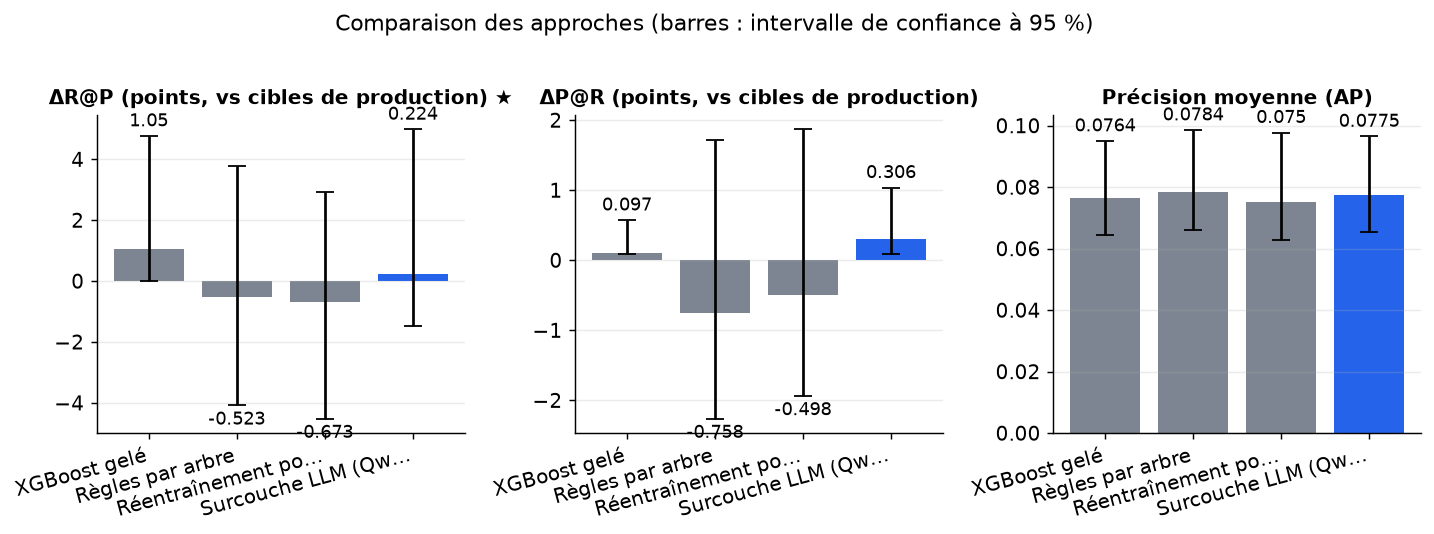

*Figure — Rappel à précision égale et précision à rappel égal (points, par rapport aux cibles de production du modèle gelé), et AP de chaque approche, avec IC à 95 % ; la barre du gelé est le niveau de départ.*

In [35]:
METRIC_LABELS = {
    "delta_recall_at_precision": "ΔR@P (points, vs cibles de production)",
    "delta_precision_at_recall": "ΔP@R (points, vs cibles de production)",
    "average_precision": "Précision moyenne (AP)",
    "rules_kept_rate": "Part des règles gardées",
    "invalid_rule_rate": "Part des règles invalides",
    "score_rank_correlation_with_frozen": "Corrélation de rang avec le gelé",
}
results = save_results({
    "primary_metric": "delta_recall_at_precision",
    "direction": "max",
    "metric_labels": METRIC_LABELS,
    "dataset": {"name": DATASET_ID if PHASE == "public" else "données internes",
                "config": DATASET_CONFIG if PHASE == "public" else "interne",
                "split": "fenêtre d'évaluation (périodes finales)", "n_examples": int(len(y_eval))},
    "approaches": result_approaches,
})
display(results_table(results))
plot_comparison(results, metrics=["delta_recall_at_precision", "delta_precision_at_recall", "average_precision"],
                caption="Rappel à précision égale et précision à rappel égal (points, par rapport aux cibles de production "
                        "du modèle gelé), et AP de chaque approche, avec IC à 95 % ; la barre du gelé est le niveau de départ.")

### Verdict automatique

Les conclusions sont écrites à l'avance et s'affichent selon les chiffres obtenus :

- **Éligibilité** : l'AP de la surcouche doit dépasser celle d'un prédicteur au hasard (le taux de fraude), sinon le résultat est **non concluant**.
- **Non-dégradation** : la borne basse de l'IC de l'écart apparié surcouche − gelé sur $\Delta R@P$ doit dépasser −0,5 point.
- **Comparaison à l'arbre** : l'écart apparié LLM − arbre est jugé par rapport à la marge de 0,3 point de l'hypothèse.

In [36]:
RECALL_LOSS_TOLERANCE = -0.5  # points : borne basse tolérée de l'IC de l'écart au gelé
TREE_MARGIN = 0.3  # points : avance maximale attendue de la surcouche LLM sur l'arbre
main_gap = point[NEW_MAIN][0] - point[FROZEN_NAME][0]
main_low, main_high = ci_pair(paired_gap(NEW_MAIN, FROZEN_NAME))
diff_low, diff_high = ci_pair(paired_gap(NEW_MAIN, TREE_NAME))
new_ap_ci = next(a for a in result_approaches if a["name"] == NEW_MAIN)["ci95"]["average_precision"]
verdicts = []
if llm_overlays[NEW_MAIN]["n_kept"] == 0:
    verdicts.append("Aucune règle LLM n'a passé le filtre : surcouche inactive (score d'origine), méthode non jugée.")
if new_ap_ci[0] <= y_eval.mean():
    verdicts.append(f"Non concluant : AP de la surcouche pas meilleure que le hasard ({y_eval.mean():.4f}).")
verdicts.append(("Non-dégradation établie" if main_low > RECALL_LOSS_TOLERANCE else "Non-dégradation NON établie")
                + f" : écart ΔR@P vs gelé = {main_gap:+.2f} pt, IC 95 % [{main_low:+.2f} ; {main_high:+.2f}].")
verdicts.append("Gain de rappel significatif." if main_low > 0 else "Pas de gain de rappel significatif (IC ≤ 0 ou contenant 0).")
if diff_low > TREE_MARGIN:
    verdicts.append(f"La surcouche LLM bat l'arbre de plus de {TREE_MARGIN} pt : seconde partie de l'hypothèse réfutée.")
elif diff_high <= TREE_MARGIN:
    verdicts.append(f"La surcouche LLM ne bat pas l'arbre de plus de {TREE_MARGIN} pt : seconde partie confirmée.")
else:
    verdicts.append("Écart LLM − arbre non concluant (l'IC chevauche la marge).")
print(f"Écart apparié LLM − arbre : {point[NEW_MAIN][0] - point[TREE_NAME][0]:+.2f} pt, "
      f"IC 95 % [{diff_low:+.2f} ; {diff_high:+.2f}]")
for verdict in verdicts:
    print("•", verdict)

Écart apparié LLM − arbre : +0.75 pt, IC 95 % [-0.92 ; +5.23]
• Non-dégradation NON établie : écart ΔR@P vs gelé = -0.82 pt, IC 95 % [-2.09 ; +1.80].
• Pas de gain de rappel significatif (IC ≤ 0 ou contenant 0).
• Écart LLM − arbre non concluant (l'IC chevauche la marge).


## 6. Analyse des résultats

### Où se joue l'écart : courbes précision-rappel et écarts par mois

- **À gauche** : les courbes précision-rappel du modèle gelé, des règles par arbre et de la surcouche LLM. Les croix marquent les trois points de fonctionnement de production. Une courbe au-dessus des autres près des croix signale un vrai gain.
- **À droite** : l'écart apparié de $\Delta R@P$ de chaque correctif au modèle gelé, mois par mois. Un gain qui s'efface avec le temps indiquerait des règles trop liées au mois d'adaptation.

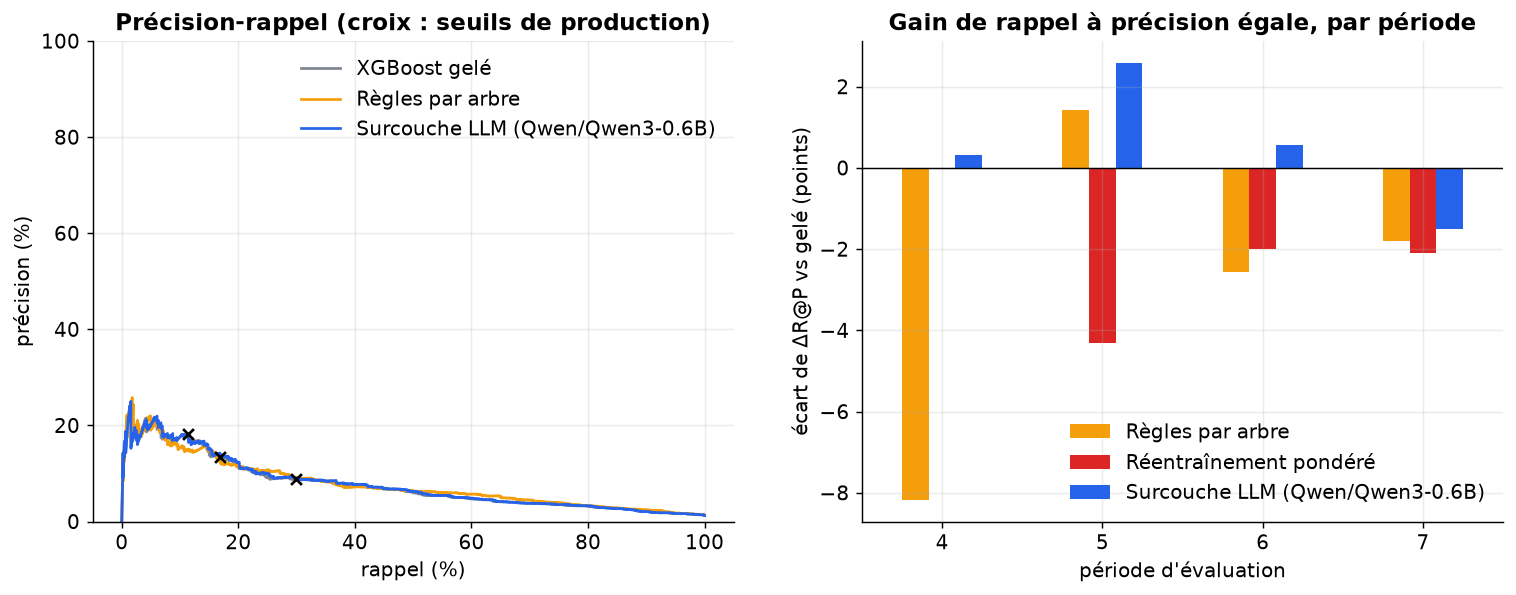

*Figure — À gauche, courbes précision-rappel sur la fenêtre d'évaluation (croix : points de fonctionnement du modèle gelé). À droite, écart de ΔR@P au modèle gelé en points, par période et par correctif ; une barre au-dessus de 0 est un gain.*

,Règles par arbre,Réentraînement pondéré,Surcouche LLM (Qwen/Qwen3-0.6B)
4,-8.17,0.00,0.33
5,1.44,-4.31,2.59
6,-2.56,-1.99,0.57
7,-1.80,-2.10,-1.50


In [37]:
months = np.unique(eval_period)
compared = [TREE_NAME, RETRAIN_NAME, NEW_MAIN]


def monthly_gap(name: str, weights: np.ndarray) -> float:
    """Écart de ΔR@P entre une approche et le gelé, sur les lignes de poids non nul (un mois)."""
    deltas = [operating_deltas(y_eval, operating_curve(y_eval, EVAL_ORDERS[n], weights), FROZEN_ALERTS, weights)[0]
              for n in (name, FROZEN_NAME)]
    return deltas[0] - deltas[1]


month_weights = [(eval_period == m).astype(float) for m in months]
monthly = pd.DataFrame({name: [monthly_gap(name, w) for w in month_weights] for name in compared}, index=months)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for name, color in [(FROZEN_NAME, COLORS["reference"]), (TREE_NAME, COLORS["accent"]), (NEW_MAIN, COLORS["new"])]:
    precision, recall = operating_curve(y_eval, EVAL_ORDERS[name], ones)
    axes[0].plot(100 * recall, 100 * precision, color=color, label=name, linewidth=1.5)
for alert in FROZEN_ALERTS:
    axes[0].scatter(100 * y_eval[alert].sum() / y_eval.sum(), 100 * y_eval[alert].mean(), color="black", marker="x", zorder=3)
axes[0].set(xlabel="rappel (%)", ylabel="précision (%)", title="Précision-rappel (croix : seuils de production)", ylim=(0, 100))
axes[0].legend()
monthly.plot.bar(ax=axes[1], color=[COLORS["accent"], COLORS["bad"], COLORS["new"]], rot=0)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="période d'évaluation", ylabel="écart de ΔR@P vs gelé (points)",
            title="Gain de rappel à précision égale, par période")
save_figure(fig, "precision_recall_and_monthly",
            "À gauche, courbes précision-rappel sur la fenêtre d'évaluation (croix : points de fonctionnement du modèle gelé). "
            "À droite, écart de ΔR@P au modèle gelé en points, par période et par correctif ; une barre au-dessus de 0 est un gain.")
display(monthly.round(2))

### Le seuil d'alerte reste-t-il valable ?

Le remappage doit garder le **volume d'alertes** à chaque seuil de production. Le tableau compare la part d'événements alertés par le modèle gelé et par la surcouche, au même seuil, sur la fenêtre d'évaluation. Il compte aussi, au seuil médian (2 %), les fraudes **gagnées** et **perdues** et les fausses alertes ajoutées ou retirées.

In [38]:
new_scores = llm_scores[NEW_MAIN]
alert_volume = pd.DataFrame({
    "part alertée visée (%)": [100 * r for r in sorted(ALERT_RATES, reverse=True)],
    "gelé (%)": [100 * a.mean() for a in FROZEN_ALERTS],
    "surcouche LLM (%)": [100 * (new_scores >= tau).mean() for tau in ALERT_THRESHOLDS]})
display(alert_volume.round(3))

frozen_alert, new_alert = FROZEN_ALERTS[1], new_scores >= ALERT_THRESHOLDS[1]  # seuil médian
swaps = pd.DataFrame([{
    "fraudes gagnées": int((new_alert & ~frozen_alert & (y_eval == 1)).sum()),
    "fraudes perdues": int((~new_alert & frozen_alert & (y_eval == 1)).sum()),
    "fausses alertes ajoutées": int((new_alert & ~frozen_alert & (y_eval == 0)).sum()),
    "fausses alertes retirées": int((~new_alert & frozen_alert & (y_eval == 0)).sum())}])
display(swaps)

,part alertée visée (%),gelé (%),surcouche LLM (%)
0,5.0,4.198,4.143
1,2.0,1.543,1.529
2,1.0,0.780,0.785


,fraudes gagnées,fraudes perdues,fausses alertes ajoutées,fausses alertes retirées
0,2,1,10,16


### Règles retenues et exemples (phase publique)

Pour juger la **lisibilité**, on affiche les règles gardées les plus fortes (lift, déclenchements sur la fenêtre d'adaptation) et quelques fraudes que la surcouche rattrape au seuil médian alors que le modèle gelé les manquait. En phase interne, seuls les nombres sont montrés : les règles portent sur des variables internes et doivent d'abord être revues par un expert métier.

In [39]:
kept_rules = pd.DataFrame([{"règle": describe_rule(rule), "lift": rule["lift"], "déclenchements": rule["fires"]}
                           for kept in llm_overlays[NEW_MAIN]["sets"] for rule in kept])
tree_kept = pd.DataFrame([{"règle": describe_rule(rule), "lift": rule["lift"], "déclenchements": rule["fires"]}
                          for rule in tree_overlay["sets"][0]]) if tree_overlay["sets"] else pd.DataFrame()
print(f"Règles LLM gardées : {len(kept_rules)} ; règles de l'arbre gardées : {len(tree_kept)}")
if PHASE == "public":
    if len(kept_rules):
        display(kept_rules.drop_duplicates("règle").sort_values("lift", ascending=False).head(10).round(2))
    if len(tree_kept):
        display(tree_kept.sort_values("lift", ascending=False).round(2))
    gained = np.where(new_alert & ~frozen_alert & (y_eval == 1))[0][:5]
    shown = UNDERWEIGHTED[:5]
    examples = pd.DataFrame(X_eval[gained][:, [FEATURE_INDEX[n] for n in shown]], columns=shown)
    examples = examples.assign(frozen_score=frozen_eval[gained], overlay_score=new_scores[gained])
    preview(examples.round(3), n=5)

Règles LLM gardées : 1 ; règles de l'arbre gardées : 4


,règle,lift,déclenchements
0,device_distinct_emails_8w >= 1.5,4.83,209


,règle,lift,déclenchements
3,housing_status_BA > 0.5 ET bank_branch_count_8...,7.48,30
2,housing_status_BA > 0.5 ET bank_branch_count_8...,4.57,1524
1,housing_status_BA <= 0.5 ET prev_address_month...,2.29,49
0,housing_status_BA <= 0.5 ET prev_address_month...,1.55,1592


### À retenir

- **Si** la borne basse de l'IC de l'écart apparié surcouche LLM − gelé sur $\Delta R@P$ dépasse −0,5 point, la promesse minimale de la source (pas de dégradation au seuil de production) tient sur ce jeu. Sinon, il ne faut pas la déployer sans autre preuve.
- **Si** l'écart apparié LLM − arbre reste sous 0,3 point, un simple arbre de profondeur 3, gratuit et déterministe, fait aussi bien. Le coût de génération et de revue des règles par LLM n'est alors pas justifié.
- **Si** le réentraînement pondéré fait mieux que les deux surcouches, la contrainte de geler le modèle a un coût mesurable. Ce coût est à mettre en regard du coût d'un redéploiement.
- **Si** aucune règle LLM ne passe le filtre, la surcouche rend le score d'origine : le dispositif est sûr mais n'apporte rien, et le taux de règles invalides dit si le modèle est en cause.
- À l'échelle réduite, un seul petit LLM fait 3 tirages : les chiffres disent si le dispositif fonctionne, pas ce que vaut l'ensemble de trois modèles.

## 7. Bilan

> **Verdict** (confiance faible). À l'échelle réduite (80 000 lignes, XGBoost à 50 arbres, un seul LLM de 0,6 Md avec 3 tirages), la surcouche LLM change à peine le score : une seule règle est gardée sur quatre valides. Son ΔR@P apparié au gelé est de −0,82 point, IC 95 % [−2,09 ; +1,80]. La non-dégradation n'est donc pas établie et aucun gain n'est démontré. L'écart avec l'arbre (+0,75 point, IC [−0,92 ; +5,23]) est non concluant, et l'arbre et le réentraînement sont eux aussi non distinguables du gelé. Le code de calcul, la réversibilité et la comparaison appariée semblent corrects, mais les chiffres ne permettent pas de trancher. Ils ne peuvent pas non plus être comparés au +2,26 de la source, obtenue sur un autre jeu et avec trois LLM.

*Échelle réduite seulement (36037 exemples, CPU) : lancement sur Colab impossible. Ces chiffres valident la mécanique ; ils sont indicatifs et à confirmer avec `SCALE = "full"`.*

| Approche | ΔR@P (points, vs cibles de production) ★ ↑ | ΔP@R (points, vs cibles de production) ↑ | Précision moyenne (AP) ↑ | Part des règles gardées | Part des règles invalides ↓ | Corrélation de rang avec le gelé | Latence médiane (ms) ↓ |
|---|---|---|---|---|---|---|---|
| XGBoost gelé (référence) | **1,05 [0 ; 4,76]** | 0,097 [0,0864 ; 0,571] | 0,0764 [0,0645 ; 0,095] | — | — | — | 1,85 |
| Règles par arbre (référence) | -0,523 [-4,09 ; 3,8] | -0,758 [-2,26 ; 1,72] | **0,0784 [0,066 ; 0,0986]** | 0,5 | — | 0,958 | 2 |
| Réentraînement pondéré (référence) | -0,673 [-4,52 ; 2,93] | -0,498 [-1,94 ; 1,87] | 0,075 [0,0627 ; 0,0977] | — | — | 0,932 | 1,83 |
| Surcouche LLM (Qwen/Qwen3-0.6B) (nouvelle approche) | 0,224 [-1,49 ; 4,98] | **0,306 [0,0903 ; 1,03]** | 0,0775 [0,0655 ; 0,0965] | 0,25 | 0,8 | 0,999 | 1,93 |

★ métrique principale · ↑ plus haut = meilleur · ↓ plus bas = meilleur · entre crochets : intervalle de confiance à 95 % (bootstrap) · en gras : la meilleure valeur.

**Réserves**

- Le petit LLM n'a fourni qu'une règle exploitable. L'écart avec le modèle gelé reflète donc cette règle et le bruit, pas la méthode décrite dans la source.
- Les gains sont mesurés avec un seuil réajusté après coup sur les données d'évaluation. Ils sont donc un peu plus favorables que ce qu'on obtiendrait en production avec le seuil fixé d'avance.

**Limites**

- Le jeu BAF est synthétique, sans vrai biais de sélection en amont : on n'y attend au mieux qu'une absence de dégradation.
- Le ΔR@P et le ΔP@R contiennent un bonus de re-choix du seuil a posteriori, commun à toutes les approches. Seuls les écarts appariés au modèle gelé mesurent le gain propre d'un correctif.
- À l'échelle réduite, un LLM de 0,6 Md avec 3 tirages juge le dispositif, pas la qualité de l'ensemble de trois modèles de la source.
- Une seule fenêtre d'adaptation (un mois) : les règles peuvent coller à ce mois et s'user ensuite.
- La lisibilité des règles et leur revue par un expert ne sont pas mesurées.

**Échelle réduite : ce qui diffère de l'échelle complète**

- Échelle réduite : 80 000 lignes tirées parmi le premier million, XGBoost à 50 arbres (300 en complet), 10 arbres de réentraînement (50), un seul LLM substitut Qwen/Qwen3-0.6B en float32 sur CPU avec 3 tirages de 400 tokens au plus (contre 3 modèles de 1,7 à 3 Md × 10 tirages), bootstrap de 200 réplicats par blocs de 500 lignes (500 réplicats, blocs de 5 000). Les trois modèles de l'échelle complète sont vérifiés par leur vrai tokeniseur et un micro-modèle à poids aléatoires.

**Améliorations possibles**

- Les ΔR@P bruts incluent un bonus de seuil commun à toutes les approches. Il faut lire l'écart au modèle gelé, dont l'IC contient 0 pour tous les correctifs.
- Avec si peu de fraudes, aucun classement entre arbre, réentraînement et surcouche n'est fiable. Ces chiffres ne permettent pas de trancher.
- Sur données internes, le détecteur évalué serait un modèle de substitution. Les gains ne seraient pas forcément ceux obtenus sur le détecteur réellement en production.

**Et ensuite ?** Rejouer le même protocole sur vos données : `PHASE = "private"`, `SCALE = "full"`, après avoir préparé le jeu et la configuration décrits dans le README (section « Sur vos données »).